In [1]:
import copy
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge



In [2]:
df = pd.read_csv('../retail.csv')
df


,Quantity,StockCode,CustomerID
0,6,85123A,17850.0
1,6,71053,17850.0
2,8,84406B,17850.0
3,6,84029G,17850.0
4,6,84029E,17850.0
...,...,...,...
397919,12,22613,12680.0
397920,6,22899,12680.0
397921,4,23254,12680.0
397922,4,23255,12680.0


In [4]:
customers_per_stock = df.groupby("StockCode")["CustomerID"].nunique()
stocks_per_customer = df.groupby("CustomerID")["StockCode"].nunique()

print("each stock has one customer:", (customers_per_stock == 1).all())
print("each customer has one stock:", (stocks_per_customer == 1).all())
display(customers_per_stock.describe())
display(stocks_per_customer.describe())


each stock has one customer: False
each customer has one stock: False


count    3665.000000
mean       72.797271
std        91.649495
min         1.000000
25%        11.000000
50%        40.000000
75%       100.000000
max       881.000000
Name: CustomerID, dtype: float64

count    4339.000000
mean       61.489283
std        85.363900
min         1.000000
25%        16.000000
50%        35.000000
75%        77.000000
max      1787.000000
Name: StockCode, dtype: float64

In [5]:
torch.manual_seed(67)

cols = ["StockCode", "CustomerID"]
X = df[cols].astype(str)
y = np.log1p(df["Quantity"].to_numpy(dtype=np.float32))

print(X.nunique())

X_tra, X_mid, y_tra, y_mid = train_test_split(
    X, y, test_size=0.2, random_state=67
)
X_val, X_tes, y_val, y_tes = train_test_split(
    X_mid, y_mid, test_size=0.5, random_state=67
)

bs = 512
lr = 1e-3
epochs = 100
patience = 5
layers = [64, 32]
emb_dim = 16


StockCode     3665
CustomerID    4339
dtype: int64


In [6]:
def target_encode(X_fit, y_fit, X):
    data = X_fit.reset_index(drop=True).copy()
    data["Quantity"] = y_fit
    return np.column_stack([
        X[col].map(data.groupby(col)["Quantity"].mean()).fillna(y_fit.mean()).to_numpy()
        for col in cols
    ])

y_raw = np.expm1(y_tra)
te_tra = np.zeros((len(X_tra), 2), dtype=np.float32)
folds = KFold(n_splits=5, shuffle=True, random_state=67)

for fit_idx, hold_idx in folds.split(X_tra):
    te_tra[hold_idx] = target_encode(
        X_tra.iloc[fit_idx], y_raw[fit_idx], X_tra.iloc[hold_idx]
    )

te_val = target_encode(X_tra, y_raw, X_val)
te_tes = target_encode(X_tra, y_raw, X_tes)

scaler = StandardScaler()
te_tra = scaler.fit_transform(te_tra).astype(np.float32)
te_val = scaler.transform(te_val).astype(np.float32)
te_tes = scaler.transform(te_tes).astype(np.float32)

best_val_loss = float("inf")
for alpha in [0.1, 1, 10, 100]:
    lin = Ridge(alpha=alpha)
    lin.fit(te_tra, y_tra)
    val_loss = np.mean((lin.predict(te_val) - y_val) ** 2)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        te_model = lin

print("target encoding val mse:", best_val_loss)


target encoding val mse: 61.691868


### Other models for part (b)

Lasso and a small histogram gradient-boosted tree use the same two target-encoded features, data splits, and log-quantity target as ridge. Lasso adds L1 regularization; boosting can learn nonlinear effects and interactions. Lasso's alpha is chosen on validation data. The boosted tree uses an internal training holdout for early stopping.

In [5]:
from time import perf_counter
from sklearn.linear_model import Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

# Same target-encoded inputs and log1p target as ridge.
# Choose lasso's alpha using validation loss only.
lasso_alphas = [0.001, 0.01, 0.1, 1.0]
lasso_losses = []
best_lasso_loss = float("inf")
lasso_start = perf_counter()

with threadpool_limits(limits=4):
    for alpha in lasso_alphas:
        candidate = Lasso(alpha=alpha, max_iter=2000)
        candidate.fit(te_tra, y_tra)
        val_loss = np.mean((candidate.predict(te_val) - y_val) ** 2)
        lasso_losses.append(float(val_loss))
        if val_loss < best_lasso_loss:
            best_lasso_loss = float(val_loss)
            lasso_model = candidate
    lasso_seconds = perf_counter() - lasso_start

    # Histogram binning and small trees keep this quick.
    # Early stopping uses a held-out portion of training data.
    boost_start = perf_counter()
    boost_model = HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=67,
    )
    boost_model.fit(te_tra, y_tra)
    boost_seconds = perf_counter() - boost_start

    te_models = {
        "target encoding + ridge": te_model,
        "target encoding + lasso": lasso_model,
        "target encoding + boosted tree": boost_model,
    }
    te_comparison = pd.DataFrame([
        {
            "model": name,
            "val log mse": np.mean((fitted.predict(te_val) - y_val) ** 2),
            "test log mse": np.mean((fitted.predict(te_tes) - y_tes) ** 2),
        }
        for name, fitted in te_models.items()
    ])
    boost_val_losses = [
        float(np.mean((prediction - y_val) ** 2))
        for prediction in boost_model.staged_predict(te_val)
    ]

best_te_name = te_comparison.loc[te_comparison["val log mse"].idxmin(), "model"]
best_te_model = te_models[best_te_name]
print(f"Lasso: alpha={lasso_model.alpha}, {lasso_seconds:.2f} seconds for all four fits")
print(f"Boosted tree: {boost_model.n_iter_} iterations, {boost_seconds:.2f} seconds")
print("Best target-encoding model by validation loss:", best_te_name)
display(te_comparison)

from pathlib import Path
Path("p2_graphs").mkdir(exist_ok=True)
te_comparison.to_csv("p2_graphs/target_encoding_models.csv", index=False)


Lasso: alpha=1.0, 0.11 seconds for all four fits
Boosted tree: 148 iterations, 1.07 seconds
Best target-encoding model by validation loss: target encoding + boosted tree


,model,val log mse,test log mse
0,target encoding + ridge,61.691765,0.800150
1,target encoding + lasso,1.002596,1.009889
2,target encoding + boosted tree,0.379324,0.378568


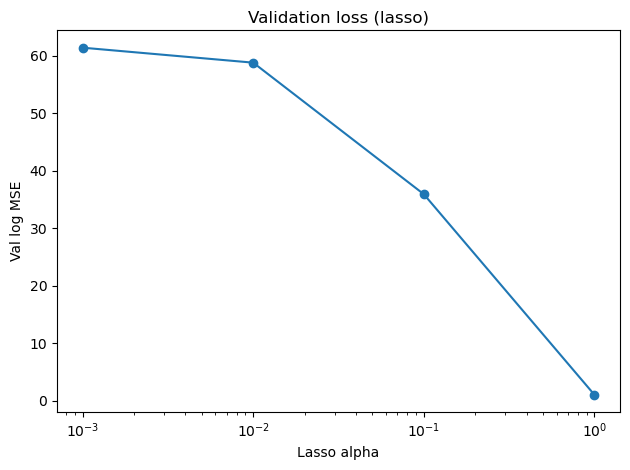

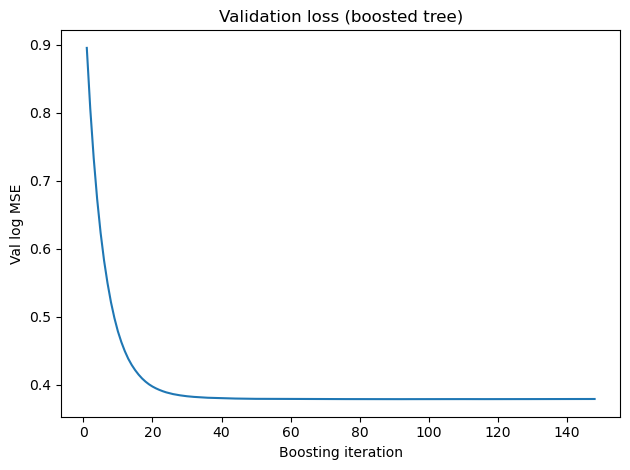

In [6]:
import matplotlib.pyplot as plt

plt.plot(lasso_alphas, lasso_losses, marker="o")
plt.xscale("log")
plt.xlabel("Lasso alpha")
plt.ylabel("Val log MSE")
plt.title("Validation loss (lasso)")
plt.tight_layout()
plt.savefig("p2_graphs/p2b_lasso.png")
plt.show()

plt.plot(range(1, len(boost_val_losses) + 1), boost_val_losses)
plt.xlabel("Boosting iteration")
plt.ylabel("Val log MSE")
plt.title("Validation loss (boosted tree)")
plt.tight_layout()
plt.savefig("p2_graphs/p2b_boosted_tree.png")
plt.show()


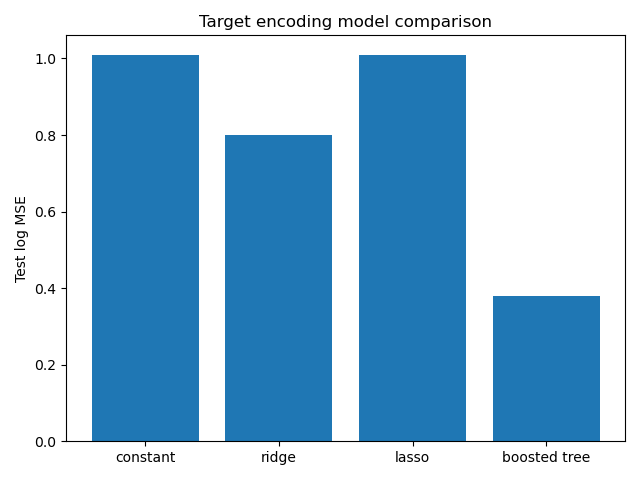

In [ ]:
import matplotlib.pyplot as plt

te_test = te_comparison.set_index("model")["test log mse"]
plt.figure()
plt.bar(
    ["constant", "ridge", "lasso", "boosted tree"],
    [
        np.mean((y_tes - y_tra.mean()) ** 2),
        te_test["target encoding + ridge"],
        te_test["target encoding + lasso"],
        te_test["target encoding + boosted tree"],
    ],
)
plt.ylabel("Test log MSE")
plt.title("Target encoding model comparison")
plt.tight_layout()
plt.savefig("p2_graphs/p2b_model_comparison.png")
plt.show()


The best target-encoding model by validation loss is **target encoding + boosted tree**, with validation log MSE **0.3793** and test log MSE **0.3786**. All three models use identical encoded features, so their comparison shows the effect of changing the model.

In [7]:
maps = {
    col: {v: i + 1 for i, v in enumerate(X_tra[col].unique())}
    for col in cols
}

def encode_ids(X):
    return np.column_stack([
        X[col].map(maps[col]).fillna(0).to_numpy(dtype=np.int64)
        for col in cols
    ])

ids_tra = encode_ids(X_tra)
ids_val = encode_ids(X_val)
ids_tes = encode_ids(X_tes)

def tensorify(ids, te, y):
    return TensorDataset(
        torch.tensor(ids, dtype=torch.long),
        torch.tensor(te, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

tra_ld = DataLoader(tensorify(ids_tra, te_tra, y_tra), batch_size=bs, shuffle=True)
val_ld = DataLoader(tensorify(ids_val, te_val, y_val), batch_size=bs)
tes_ld = DataLoader(tensorify(ids_tes, te_tes, y_tes), batch_size=bs)

class RetailModel(nn.Module):
    def __init__(self, use_te=False):
        super().__init__()
        self.use_te = use_te
        self.stock = nn.Embedding(len(maps[cols[0]]) + 1, emb_dim, padding_idx=0)
        self.customer = nn.Embedding(len(maps[cols[1]]) + 1, emb_dim, padding_idx=0)
        modules = []
        in_features = 2 * emb_dim + (2 if use_te else 0)
        for width in layers:
            modules.append(nn.Linear(in_features, width))
            modules.append(nn.ReLU())
            in_features = width
        modules.append(nn.Linear(in_features, 1))
        self.net = nn.Sequential(*modules)

    def forward(self, ids, te):
        x = torch.cat([self.stock(ids[:, 0]), self.customer(ids[:, 1])], dim=1)
        if self.use_te:
            x = torch.cat([x, te], dim=1)
        return self.net(x).squeeze(1)


In [8]:
los = nn.MSELoss()

@torch.no_grad()
def eval(model, ld):
    model.eval()
    tot_los = 0.0
    for ids, te, y in ld:
        tot_los += los(model(ids, te), y).item() * len(y)
    return tot_los / len(ld.dataset)

def fit(model):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss = float("inf")
    best_model = None
    val_losses = []
    wait = 0
    for epo in range(epochs):
        model.train()
        for ids, te, y in tra_ld:
            opt.zero_grad()
            loss = los(model(ids, te), y)
            loss.backward()
            opt.step()
        val_loss = eval(model, val_ld)
        val_losses.append(val_loss)
        print(f"epoch: {epo + 1}, val_loss: {val_loss}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break
    model.load_state_dict(best_model)
    return model, val_losses

emb_model, emb_losses = fit(RetailModel())


epoch: 1, val_loss: 0.693033181858868
epoch: 2, val_loss: 0.4674418867113699
epoch: 3, val_loss: 0.37163970987625183
epoch: 4, val_loss: 0.3365215274779059
epoch: 5, val_loss: 0.3190575997645854
epoch: 6, val_loss: 0.3099159851196927
epoch: 7, val_loss: 0.3060217846767654
epoch: 8, val_loss: 0.3016803315546698
epoch: 9, val_loss: 0.2995145598603963
epoch: 10, val_loss: 0.2995827971666656
epoch: 11, val_loss: 0.29584128379366414
epoch: 12, val_loss: 0.2968719020623685
epoch: 13, val_loss: 0.295087388488582
epoch: 14, val_loss: 0.292923622788988
epoch: 15, val_loss: 0.2936138650248891
epoch: 16, val_loss: 0.29381354913492974
epoch: 17, val_loss: 0.29157108408790255
epoch: 18, val_loss: 0.2923557921962466
epoch: 19, val_loss: 0.2929916351039006
epoch: 20, val_loss: 0.2924739093630967
epoch: 21, val_loss: 0.2928806837778471
epoch: 22, val_loss: 0.2909699961405276
epoch: 23, val_loss: 0.2927933840098322
epoch: 24, val_loss: 0.29006252440526203
epoch: 25, val_loss: 0.28952751664282284
epoch:

In [9]:
combined_model, combined_losses = fit(RetailModel(use_te=True))


epoch: 1, val_loss: 44.170671586583886
epoch: 2, val_loss: 8.634455697396024
epoch: 3, val_loss: 3.976923491708428
epoch: 4, val_loss: 3.80732681649873
epoch: 5, val_loss: 2.233456027048824
epoch: 6, val_loss: 3.085849328103629
epoch: 7, val_loss: 3.0955208031993147
epoch: 8, val_loss: 2.6842772984809073
epoch: 9, val_loss: 2.4039904730994395
epoch: 10, val_loss: 2.0083661928359504
epoch: 11, val_loss: 2.4040044630129844
epoch: 12, val_loss: 2.7500142097820657
epoch: 13, val_loss: 1.6019147697538076
epoch: 14, val_loss: 1.0829184838792718
epoch: 15, val_loss: 2.5298980717132693
epoch: 16, val_loss: 1.197659947472401
epoch: 17, val_loss: 1.964799755019599
epoch: 18, val_loss: 0.6645486775200004
epoch: 19, val_loss: 1.2282805755812334
epoch: 20, val_loss: 1.8849348103096555
epoch: 21, val_loss: 1.5524720384094866
epoch: 22, val_loss: 1.0516020460844424
epoch: 23, val_loss: 0.6782312515717124


In [ ]:
results = pd.concat([
    pd.DataFrame({
        "model": ["constant"],
        "test log mse": [np.mean((y_tes - y_tra.mean()) ** 2)],
    }),
    te_comparison[["model", "test log mse"]],
    pd.DataFrame({
        "model": ["embeddings", "combined"],
        "test log mse": [eval(emb_model, tes_ld), eval(combined_model, tes_ld)],
    }),
], ignore_index=True)
display(results)


,model,test log mse
0,constant,1.009889
1,target encoding + ridge,0.800150
2,target encoding + lasso,1.009889
3,target encoding + boosted tree,0.378568
4,embeddings,0.289678
5,combined,0.291138


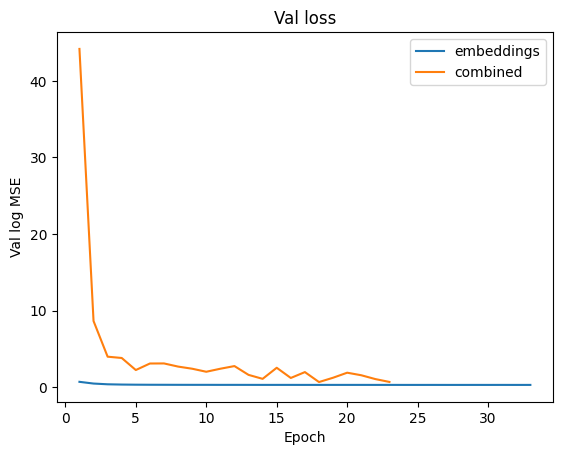

In [12]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(emb_losses) + 1), emb_losses, label="embeddings")
plt.plot(range(1, len(combined_losses) + 1), combined_losses, label="combined")
plt.xlabel("Epoch")
plt.ylabel("Val log MSE")
plt.title("Val loss")
plt.legend()
plt.show()
